# 01 · Exploring tire degradation

**Goal:** measure how much slower each tire compound gets per lap of use, after correcting for the car getting lighter as it burns fuel.

Data: `app/data/clean_laps.parquet`, exported from `ANALYTICS.CLEAN_LAPS` in Snowflake (no lap 1, no pit laps, no safety car or incident laps, dry tires only). Re-run `pipeline/export_app_data.py` to refresh it.

In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from degradation import fit_degradation, simulate_races

COMPOUND_COLORS = {"SOFT": "#E10600", "MEDIUM": "#F5C400", "HARD": "#9A9A9A"}

laps = pd.read_parquet(Path("..") / "app" / "data" / "clean_laps.parquet")
print(f"{len(laps):,} clean laps")
laps.groupby(["SEASON", "COMPOUND"]).size().unstack()

80,441 clean laps


COMPOUND,HARD,MEDIUM,SOFT
SEASON,,,
2023,10678,7146,2762
2024,12589,7653,1491
2025,9776,9236,2770
2026,7183,5742,3415


## 1. One driver's race

Lap times through a single race, colored by tire. Change `SEASON`, `ROUND`, and `DRIVER` to explore. Look for two things within each stint: the slow upward drift (tire wear), and the overall downward trend across the race (fuel burning off).

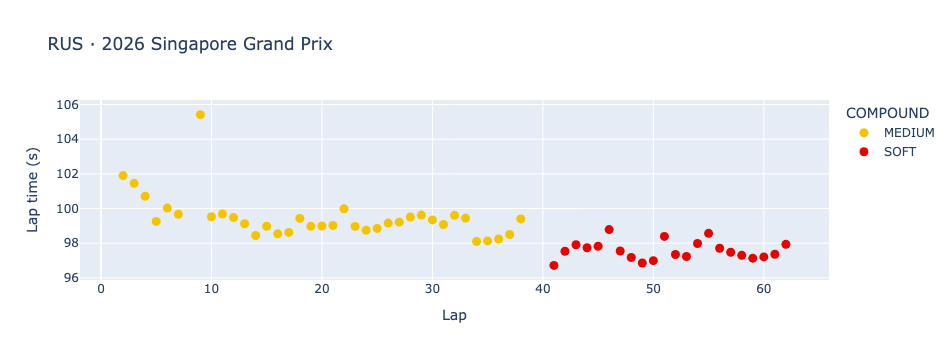

In [2]:
SEASON = int(laps["SEASON"].max())
ROUND = int(laps.loc[laps["SEASON"] == SEASON, "RACE_ROUND"].max())   # most recent race
race = laps[(laps["SEASON"] == SEASON) & (laps["RACE_ROUND"] == ROUND)]
DRIVER = race["DRIVER_CODE"].value_counts().index[0]                 # driver with most clean laps

one = race[race["DRIVER_CODE"] == DRIVER]
fig = px.scatter(one, x="LAP_NUMBER", y="LAP_TIME_SEC", color="COMPOUND",
                 color_discrete_map=COMPOUND_COLORS, hover_data=["TYRE_LIFE", "STINT"],
                 title=f"{DRIVER} · {SEASON} {one['EVENT_NAME'].iloc[0]}",
                 labels={"LAP_NUMBER": "Lap", "LAP_TIME_SEC": "Lap time (s)"})
fig.update_traces(marker_size=9)
fig.show()

## 2. The naive view: pace vs. tire age

Average pace by tire age, across this season's races. `PACE_RATIO` divides each lap by its race's median lap, so circuits are comparable: 0% is a typical lap for that race, +1% is about 0.9 s slower on a 90-second lap.

If tires simply got slower with age, every line would slope clearly upward. Expect something flatter, and possibly a line sloping down.

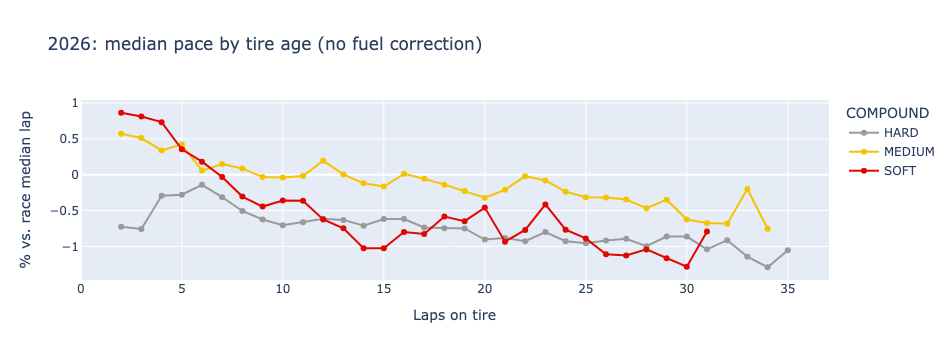

In [3]:
cur = laps[laps["SEASON"] == SEASON].copy()
cur["PACE_PCT"] = (cur["PACE_RATIO"] - 1) * 100

curve = (cur[cur["TYRE_LIFE"] <= 35]
         .groupby(["COMPOUND", "TYRE_LIFE"], as_index=False)
         .agg(PACE_PCT=("PACE_PCT", "median"), LAPS=("PACE_PCT", "size")))
curve = curve[curve["LAPS"] >= 30]   # skip tire ages with too few laps to trust

fig = px.line(curve, x="TYRE_LIFE", y="PACE_PCT", color="COMPOUND", markers=True,
              color_discrete_map=COMPOUND_COLORS, hover_data=["LAPS"],
              title=f"{SEASON}: median pace by tire age (no fuel correction)",
              labels={"TYRE_LIFE": "Laps on tire", "PACE_PCT": "% vs. race median lap"})
fig.show()

## 3. Why the naive view misleads: fuel

Cars start with about 100 kg of fuel and get faster as it burns. Old tires tend to be used late in a race, when cars are light, so fuel savings hide tire wear.

Within a single stint, the two can't be separated at all: every lap, tire age and lap number both go up by exactly one. They become separable only by comparing **different stints** in the same driver's race. A tire that's 5 laps old on lap 10 and another that's 5 laps old on lap 40 differ only in fuel load.

So the model compares laps **within each driver's race** (which cancels out car speed, circuit, and weather) and estimates three things together:

- **fuel:** change in pace per lap of the race (expected negative: faster as fuel burns)
- **wear per compound:** change in pace per lap of tire age (expected positive)
- **offset per compound:** how much faster or slower a fresh set of each compound is than mediums

### Check the method on simulated data first

Before trusting it on real races, fit it to fake races where we *set* the true answer. A method that can't recover a known answer can't be trusted on an unknown one.

In [4]:
TRUE = {"fuel": -0.065, "SOFT": 0.11, "MEDIUM": 0.065, "HARD": 0.035}   # % per lap
sim = simulate_races(TRUE)

corrected = fit_degradation(sim)
naive = fit_degradation(sim, fuel_correction=False)
check = pd.DataFrame({
    "true value": [TRUE["fuel"], TRUE["SOFT"], TRUE["MEDIUM"], TRUE["HARD"]],
    "with fuel correction": [corrected["fuel"], corrected["deg_SOFT"],
                             corrected["deg_MEDIUM"], corrected["deg_HARD"]],
    "naive (no fuel term)": [None, naive["deg_SOFT"], naive["deg_MEDIUM"], naive["deg_HARD"]],
}, index=["fuel", "wear SOFT", "wear MEDIUM", "wear HARD"])
check.round(3)

,true value,with fuel correction,naive (no fuel term)
fuel,-0.065,-0.065,NaN
wear SOFT,0.110,0.110,0.037
wear MEDIUM,0.065,0.065,0.009
wear HARD,0.035,0.035,-0.036


The corrected model recovers the true values. The naive one underestimates wear badly, and can even conclude that hard tires get *faster* with age.

## 4. Fit the real data

Fit this season separately from earlier ones: the 2026 rules brought new cars and narrower tires, so the numbers may differ. Results are converted from % to seconds using a 90-second reference lap.

In [5]:
REF_LAP = 90  # seconds, to translate % into something intuitive

fits = pd.DataFrame({
    f"{SEASON}": fit_degradation(laps[laps["SEASON"] == SEASON]),
    f"before {SEASON}": fit_degradation(laps[laps["SEASON"] < SEASON]),
}).T

seconds = fits[["fuel", "deg_SOFT", "deg_MEDIUM", "deg_HARD"]] * REF_LAP / 100
seconds.columns = ["fuel (s/lap)", "SOFT wear (s/lap)", "MEDIUM wear (s/lap)", "HARD wear (s/lap)"]
seconds["laps used"] = fits["laps_used"].astype(int)
seconds.round(3)

,fuel (s/lap),SOFT wear (s/lap),MEDIUM wear (s/lap),HARD wear (s/lap),laps used
2026,-0.043,0.005,0.028,0.026,16340
before 2026,-0.054,0.059,0.036,0.034,64101


**How to read this:** a SOFT wear value of 0.08 means each extra lap on a set of softs costs about 0.08 s. After 20 laps, that's 1.6 s per lap slower than when they were new. Fuel should be negative, typically a few hundredths of a second per lap.

**Sanity checks:** softs should wear fastest and hards slowest. If not, that's a finding to investigate rather than a result to report.

## 5. The corrected degradation curves

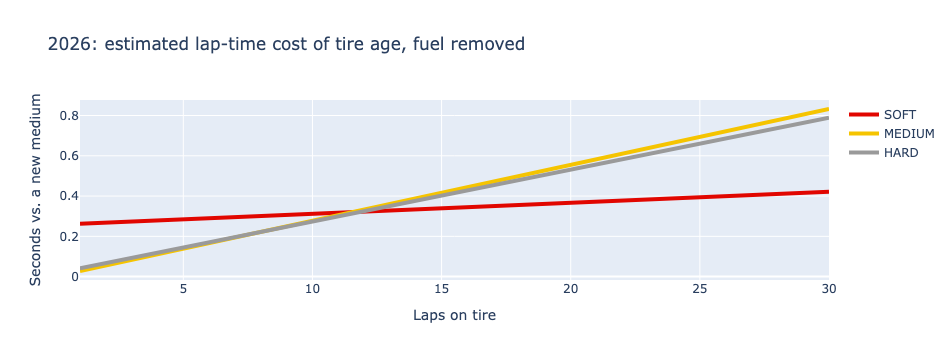

In [6]:
row = fits.loc[f"{SEASON}"]
ages = list(range(1, 31))
fig = go.Figure()
for c in ["SOFT", "MEDIUM", "HARD"]:
    offset = row.get(f"offset_{c}", 0.0)   # MEDIUM is the baseline (offset 0)
    loss = [(offset + row[f"deg_{c}"] * a) * REF_LAP / 100 for a in ages]
    fig.add_trace(go.Scatter(x=ages, y=loss, name=c, mode="lines",
                             line=dict(color=COMPOUND_COLORS[c], width=4)))
fig.update_layout(title=f"{SEASON}: estimated lap-time cost of tire age, fuel removed",
                  xaxis_title="Laps on tire", yaxis_title="Seconds vs. a new medium",
                  hovermode="x unified")
fig.show()

Where two lines cross is where one compound stops being faster than another, which is the start of a strategy question.

## What's next

- **Uncertainty:** add confidence ranges (bootstrapping by race) so results read "0.08 ± 0.02 s/lap".
- **Team-specific rates:** let each team's wear differ from the field average, with partial pooling for teams with few laps.
- **Out-of-sample test:** fit on earlier races, predict later ones, and measure the error.
- **Strategy:** combine wear, fuel, and pit-lane time loss to compare one-stop and two-stop plans.